# MIT ACADEMY OF ENGINEERING, ALANDI

## AIML MDM

### Practical Assignment

**Title:** Regression Models and Gradient Descent Optimization

**Submitted By:** Shravani Birajdar

**Branch:** Electronics and Telecommunication Engineering (ENTC)

**Year:** Second Year B.Tech

**Subject:** Artificial Intelligence and Machine Learning (AIML MDM)

### Assignment Questions

1. Develop Regression Models for a real-world application and evaluate their performance using appropriate metrics.

2. Implement and analyze the performance of Gradient Descent optimization for Linear Regression.

### Dataset
Student Performance Dataset

### Academic Year
2026–2027

In [2]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Machine Learning libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline

# Evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Display settings
pd.set_option('display.max_columns', None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# Upload the CSV dataset to Google Colab

from google.colab import files

uploaded = files.upload()

Saving student_performance_dataset.csv to student_performance_dataset.csv


In [5]:
# Read the uploaded CSV file

df = pd.read_csv('/student_performance_dataset.csv')

# Display the first five rows
df.head()

,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,1,Male,4.0,98.0,6.5,Bachelors,Yes,Yes,No,76.9,100.0,A
1,2,Female,6.3,100.0,5.7,High School,Yes,Yes,Yes,75.5,100.0,A
2,3,Male,4.9,85.3,7.9,Bachelors,Yes,No,Yes,88.5,97.3,A
3,4,Male,2.6,77.5,8.0,NaN,Yes,Yes,No,85.1,83.8,B
4,5,Male,2.2,89.6,4.6,Bachelors,Yes,No,Yes,61.8,68.3,D


In [6]:
# Check the number of rows and columns

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1000
Number of columns: 12


In [7]:
# Display information about columns, data types and non-null values

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  1000 non-null   int64  
 1   gender                      1000 non-null   object 
 2   study_time_hours            1000 non-null   float64
 3   attendance_percent          1000 non-null   float64
 4   sleep_hours                 1000 non-null   float64
 5   parental_education          898 non-null    object 
 6   internet_access             1000 non-null   object 
 7   extracurricular_activities  1000 non-null   object 
 8   part_time_job               1000 non-null   object 
 9   previous_grade              1000 non-null   float64
 10  final_exam_score            1000 non-null   float64
 11  final_grade                 1000 non-null   object 
dtypes: float64(5), int64(1), object(6)
memory usage: 93.9+ KB


In [8]:
# Display statistical summary of numerical columns

df.describe()

,student_id,study_time_hours,attendance_percent,sleep_hours,previous_grade,final_exam_score
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,3.570700,85.092300,6.799500,69.740900,83.543500
std,288.819436,1.478559,9.270685,1.203527,12.613425,10.341333
min,1.000000,0.500000,54.800000,3.200000,31.300000,46.800000
25%,250.750000,2.600000,78.800000,5.900000,61.000000,76.075000
50%,500.500000,3.600000,85.200000,6.800000,69.600000,83.800000
75%,750.250000,4.500000,91.900000,7.600000,78.400000,91.525000
max,1000.000000,8.100000,100.000000,10.000000,100.000000,100.000000


In [9]:
# Check for missing values in each column

print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
student_id                      0
gender                          0
study_time_hours                0
attendance_percent              0
sleep_hours                     0
parental_education            102
internet_access                 0
extracurricular_activities      0
part_time_job                   0
previous_grade                  0
final_exam_score                0
final_grade                     0
dtype: int64


In [10]:
# Check for duplicate records

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


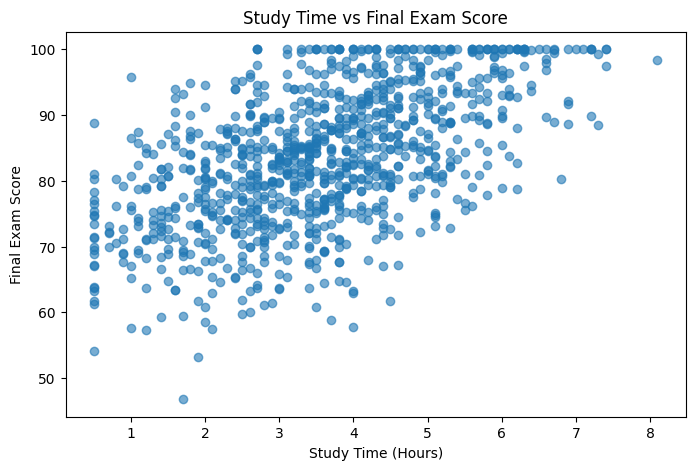

In [11]:
# Visualize the relationship between study time and final exam score

plt.figure(figsize=(8, 5))

plt.scatter(
    df['study_time_hours'],
    df['final_exam_score'],
    alpha=0.6
)

plt.xlabel('Study Time (Hours)')
plt.ylabel('Final Exam Score')
plt.title('Study Time vs Final Exam Score')

plt.show()

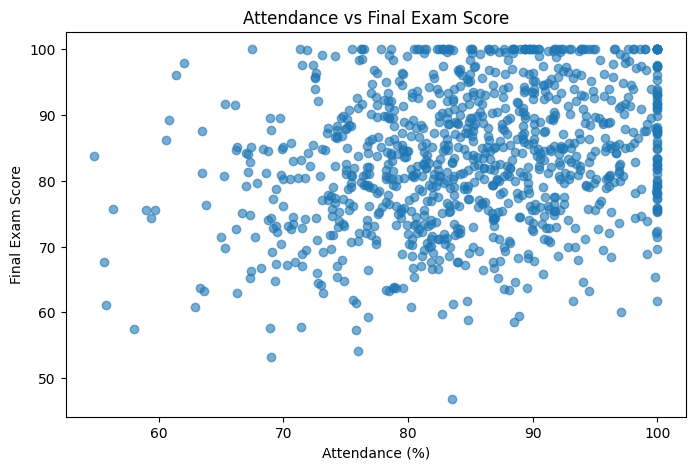

In [12]:
# Visualize the relationship between attendance and final exam score

plt.figure(figsize=(8, 5))

plt.scatter(
    df['attendance_percent'],
    df['final_exam_score'],
    alpha=0.6
)

plt.xlabel('Attendance (%)')
plt.ylabel('Final Exam Score')
plt.title('Attendance vs Final Exam Score')

plt.show()

## Feature Selection

The objective is to predict the student's final exam score.

Numerical features selected for prediction:

- Study time
- Attendance percentage
- Sleep hours
- Previous grade

Target variable:

- Final exam score

In [13]:
# Select input features

X = df[
    [
        'study_time_hours',
        'attendance_percent',
        'sleep_hours',
        'previous_grade'
    ]
]

# Select target variable

y = df['final_exam_score']

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   study_time_hours  attendance_percent  sleep_hours  previous_grade
0               4.0                98.0          6.5            76.9
1               6.3               100.0          5.7            75.5
2               4.9                85.3          7.9            88.5
3               2.6                77.5          8.0            85.1
4               2.2                89.6          4.6            61.8

Target:
0    100.0
1    100.0
2     97.3
3     83.8
4     68.3
Name: final_exam_score, dtype: float64


## Train-Test Split

The dataset is divided into:

- 80% training data
- 20% testing data

The training data is used to learn the model, while the testing data is used to evaluate its performance on unseen data.

In [14]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 800
Testing samples: 200


## Linear Regression

Linear Regression models the relationship between input features and a continuous target variable.

The model attempts to find a linear relationship that minimizes the prediction error.

Linear Regression is suitable because the target variable, final exam score, is continuous.

In [15]:
# Create the Linear Regression model

linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train, y_train)

# Predict final exam scores
y_pred_linear = linear_model.predict(X_test)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


## Polynomial Regression

Polynomial Regression extends Linear Regression by adding polynomial terms of the input features.

It can model nonlinear relationships between the input variables and the target variable.

In [16]:
# Create Polynomial Regression model

polynomial_model = Pipeline([
    ('polynomial_features', PolynomialFeatures(degree=2)),
    ('linear_regression', LinearRegression())
])

# Train the model
polynomial_model.fit(X_train, y_train)

# Make predictions
y_pred_poly = polynomial_model.predict(X_test)

print("Polynomial Regression model trained successfully.")

Polynomial Regression model trained successfully.


## Ridge Regression

Ridge Regression is a regularized version of Linear Regression.

It adds a penalty to large model coefficients, which can help reduce overfitting.

The regularization parameter is represented by alpha.

In [17]:
# Create Ridge Regression model

ridge_model = Ridge(alpha=1.0)

# Train the model
ridge_model.fit(X_train, y_train)

# Make predictions
y_pred_ridge = ridge_model.predict(X_test)

print("Ridge Regression model trained successfully.")

Ridge Regression model trained successfully.


In [18]:
# Function to calculate regression performance metrics

def evaluate_model(y_actual, y_pred):

    mae = mean_absolute_error(y_actual, y_pred)
    mse = mean_squared_error(y_actual, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_actual, y_pred)

    return mae, mse, rmse, r2

In [19]:
# Evaluate Linear Regression

linear_metrics = evaluate_model(y_test, y_pred_linear)

# Evaluate Polynomial Regression

poly_metrics = evaluate_model(y_test, y_pred_poly)

# Evaluate Ridge Regression

ridge_metrics = evaluate_model(y_test, y_pred_ridge)

print("Linear Regression")
print("MAE :", linear_metrics[0])
print("MSE :", linear_metrics[1])
print("RMSE:", linear_metrics[2])
print("R²   :", linear_metrics[3])

print("\nPolynomial Regression")
print("MAE :", poly_metrics[0])
print("MSE :", poly_metrics[1])
print("RMSE:", poly_metrics[2])
print("R²   :", poly_metrics[3])

print("\nRidge Regression")
print("MAE :", ridge_metrics[0])
print("MSE :", ridge_metrics[1])
print("RMSE:", ridge_metrics[2])
print("R²   :", ridge_metrics[3])

Linear Regression
MAE : 4.998893041872424
MSE : 41.48134771715001
RMSE: 6.440601502744135
R²   : 0.6146179845263231

Polynomial Regression
MAE : 5.115266496849938
MSE : 42.68355133136906
RMSE: 6.533264982485331
R²   : 0.6034489247595902

Ridge Regression
MAE : 4.999268194159853
MSE : 41.484073468417144
RMSE: 6.440813106154932
R²   : 0.6145926609634491


In [20]:
# Create a comparison table for all regression models

results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Polynomial Regression',
        'Ridge Regression'
    ],

    'MAE': [
        linear_metrics[0],
        poly_metrics[0],
        ridge_metrics[0]
    ],

    'MSE': [
        linear_metrics[1],
        poly_metrics[1],
        ridge_metrics[1]
    ],

    'RMSE': [
        linear_metrics[2],
        poly_metrics[2],
        ridge_metrics[2]
    ],

    'R2 Score': [
        linear_metrics[3],
        poly_metrics[3],
        ridge_metrics[3]
    ]
})

results

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,4.998893,41.481348,6.440602,0.614618
1,Polynomial Regression,5.115266,42.683551,6.533265,0.603449
2,Ridge Regression,4.999268,41.484073,6.440813,0.614593


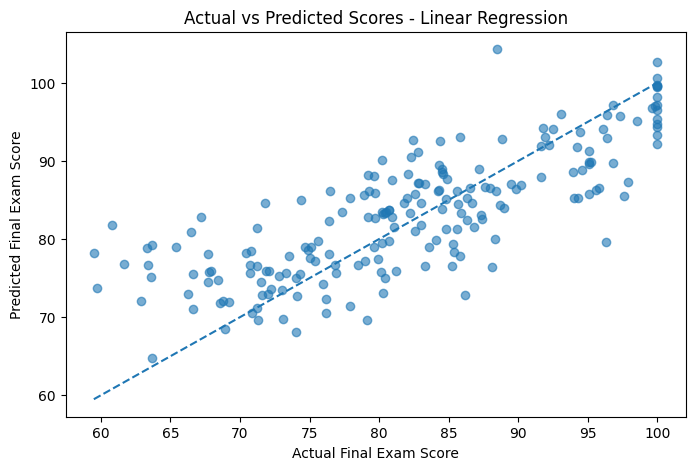

In [21]:
# Plot actual versus predicted scores for Linear Regression

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_linear, alpha=0.6)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel('Actual Final Exam Score')
plt.ylabel('Predicted Final Exam Score')
plt.title('Actual vs Predicted Scores - Linear Regression')

plt.show()

# Gradient Descent Optimization for Linear Regression

Gradient Descent is an optimization algorithm used to find model parameters that minimize the cost function.

For simple Linear Regression:

y = mx + b

where:

m = slope
b = intercept

The Mean Squared Error (MSE) can be used as the cost function.

Gradient Descent repeatedly updates m and b in the direction that reduces the cost.

The learning rate controls the size of each update.

In [22]:
# Select study time as the input feature
# and final exam score as the target

X_gd = df['study_time_hours'].values
y_gd = df['final_exam_score'].values

print("Number of samples:", len(X_gd))
print("Input feature: Study Time")
print("Target: Final Exam Score")

Number of samples: 1000
Input feature: Study Time
Target: Final Exam Score


## Feature Scaling

Gradient Descent performs better when numerical features are on a similar scale.

Therefore, the study-time feature is standardized before applying Gradient Descent.

In [23]:
# Standardize the input feature

X_mean = X_gd.mean()
X_std = X_gd.std()

X_scaled = (X_gd - X_mean) / X_std

print("Mean after scaling:", X_scaled.mean())
print("Standard deviation after scaling:", X_scaled.std())

Mean after scaling: 7.105427357601002e-18
Standard deviation after scaling: 1.0


## Manual Implementation of Gradient Descent

The parameters are initialized as:

m = 0
b = 0

For every iteration:

1. Calculate predictions.
2. Calculate the cost.
3. Calculate gradients.
4. Update m and b.
5. Store the cost for analysis.

The process continues until the specified number of iterations is completed.

In [24]:
# Initialize parameters

m = 0
b = 0

# Learning rate
learning_rate = 0.01

# Number of iterations
iterations = 1000

# Number of training samples
n = len(X_scaled)

# Store cost values for visualization
cost_history = []

# Gradient Descent loop

for i in range(iterations):

    # Calculate predictions
    y_pred = m * X_scaled + b

    # Calculate error
    error = y_pred - y_gd

    # Calculate Mean Squared Error cost
    cost = np.mean(error ** 2)

    # Store cost
    cost_history.append(cost)

    # Calculate gradients
    dm = (2 / n) * np.sum(X_scaled * error)
    db = (2 / n) * np.sum(error)

    # Update parameters
    m = m - learning_rate * dm
    b = b - learning_rate * db

print("Gradient Descent completed.")
print("Final slope:", m)
print("Final intercept:", b)
print("Final cost:", cost_history[-1])

Gradient Descent completed.
Final slope: 5.865907494430621
Final intercept: 83.54349985939902
Final cost: 72.42734690096468


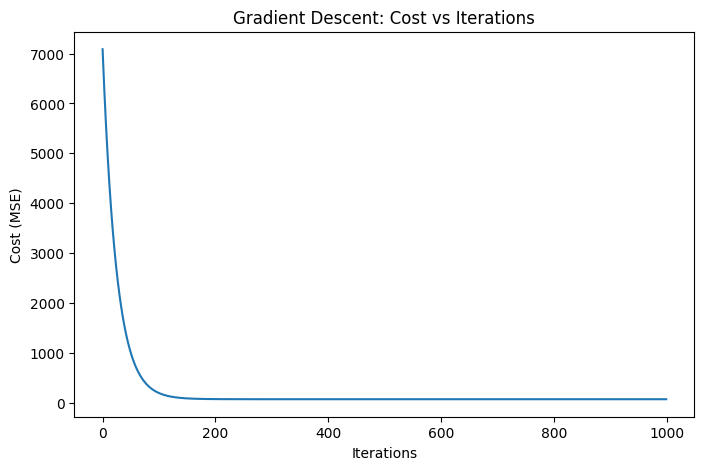

In [25]:
# Plot cost against number of iterations

plt.figure(figsize=(8, 5))

plt.plot(cost_history)

plt.xlabel('Iterations')
plt.ylabel('Cost (MSE)')
plt.title('Gradient Descent: Cost vs Iterations')

plt.show()

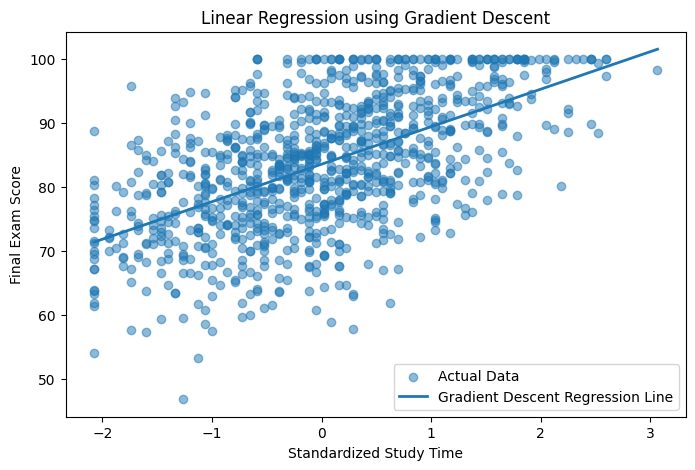

In [26]:
# Calculate predictions using the final Gradient Descent parameters

y_pred_gd = m * X_scaled + b

# Plot actual data and Gradient Descent regression line

plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled,
    y_gd,
    alpha=0.5,
    label='Actual Data'
)

# Sort values for a clean regression line
sorted_indices = np.argsort(X_scaled)

plt.plot(
    X_scaled[sorted_indices],
    y_pred_gd[sorted_indices],
    linewidth=2,
    label='Gradient Descent Regression Line'
)

plt.xlabel('Standardized Study Time')
plt.ylabel('Final Exam Score')
plt.title('Linear Regression using Gradient Descent')

plt.legend()
plt.show()

In [27]:
# Calculate performance metrics for Gradient Descent

mae_gd = mean_absolute_error(y_gd, y_pred_gd)
mse_gd = mean_squared_error(y_gd, y_pred_gd)
rmse_gd = np.sqrt(mse_gd)
r2_gd = r2_score(y_gd, y_pred_gd)

print("Gradient Descent Performance")
print("----------------------------")
print("MAE :", mae_gd)
print("MSE :", mse_gd)
print("RMSE:", rmse_gd)
print("R²  :", r2_gd)

Gradient Descent Performance
----------------------------
MAE : 6.831781277282858
MSE : 72.42734690096468
RMSE: 8.510425776714387
R²  : 0.32207121867186583


In [28]:
# Train a standard Linear Regression model using the same single feature

standard_model = LinearRegression()

standard_model.fit(
    X_scaled.reshape(-1, 1),
    y_gd
)

# Predictions
y_pred_standard = standard_model.predict(
    X_scaled.reshape(-1, 1)
)

# Calculate metrics
standard_mae = mean_absolute_error(y_gd, y_pred_standard)
standard_mse = mean_squared_error(y_gd, y_pred_standard)
standard_rmse = np.sqrt(standard_mse)
standard_r2 = r2_score(y_gd, y_pred_standard)

print("Standard Linear Regression")
print("--------------------------")
print("MAE :", standard_mae)
print("MSE :", standard_mse)
print("RMSE:", standard_rmse)
print("R²  :", standard_r2)

print("\nGradient Descent")
print("----------------")
print("MAE :", mae_gd)
print("MSE :", mse_gd)
print("RMSE:", rmse_gd)
print("R²  :", r2_gd)

Standard Linear Regression
--------------------------
MAE : 6.831781271948661
MSE : 72.42734690096465
RMSE: 8.510425776714385
R²  : 0.32207121867186617

Gradient Descent
----------------
MAE : 6.831781277282858
MSE : 72.42734690096468
RMSE: 8.510425776714387
R²  : 0.32207121867186583


## Effect of Learning Rate

The learning rate determines how large each parameter update is during Gradient Descent.

A very small learning rate can make convergence slow.

A suitable learning rate allows the cost to decrease steadily.

A very large learning rate can cause unstable learning or prevent convergence.

In [29]:
# Function to perform Gradient Descent for a given learning rate

def gradient_descent(X, y, learning_rate, iterations):

    m = 0
    b = 0

    n = len(X)
    cost_history = []

    for i in range(iterations):

        # Prediction
        y_pred = m * X + b

        # Error
        error = y_pred - y

        # Cost
        cost = np.mean(error ** 2)
        cost_history.append(cost)

        # Gradients
        dm = (2 / n) * np.sum(X * error)
        db = (2 / n) * np.sum(error)

        # Parameter updates
        m = m - learning_rate * dm
        b = b - learning_rate * db

    return m, b, cost_history

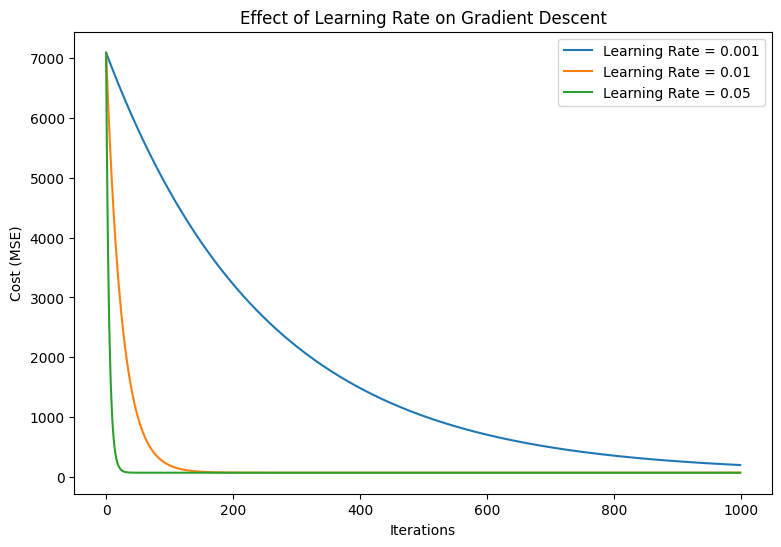

In [30]:
# Test different learning rates

learning_rates = [0.001, 0.01, 0.05]

plt.figure(figsize=(9, 6))

for lr in learning_rates:

    m_temp, b_temp, costs = gradient_descent(
        X_scaled,
        y_gd,
        lr,
        1000
    )

    plt.plot(
        costs,
        label=f'Learning Rate = {lr}'
    )

plt.xlabel('Iterations')
plt.ylabel('Cost (MSE)')
plt.title('Effect of Learning Rate on Gradient Descent')

plt.legend()
plt.show()

# Conclusion

In this experiment, regression models were developed to predict students' final examination scores using academic and lifestyle-related features.

Linear Regression, Polynomial Regression, and Ridge Regression were implemented and evaluated using MAE, MSE, RMSE and R² Score.

The models were compared based on their prediction errors and R² scores.

Gradient Descent was then implemented manually for Linear Regression. The cost function was monitored over multiple iterations. The decreasing cost demonstrated that the optimization process was successfully reducing prediction error.

The effect of different learning rates was also analyzed. The experiment showed that the learning rate has an important effect on the convergence speed and stability of Gradient Descent.

Overall, the experiment demonstrates how regression models can be applied to a real-world student performance problem and how Gradient Descent can be used as an optimization technique for Linear Regression.

# Key Findings

- Regression models can be used to predict continuous student examination scores.
- MAE, MSE and RMSE measure prediction error, where lower values indicate lower error.
- R² Score measures how well the model explains the variation in the target variable.
- Polynomial Regression can capture nonlinear relationships.
- Ridge Regression applies regularization to reduce the effect of large coefficients.
- Gradient Descent iteratively updates model parameters to minimize the cost function.
- The cost generally decreases as Gradient Descent converges.
- The learning rate affects the speed and stability of convergence.